Enter initial window size (odd number):  9
Enter maximum window size (odd number):  99


C:\Users\aasth\AppData\Local\Temp\ipykernel_31968\3653584067.py:59: RuntimeWarning: overflow encountered in scalar subtract
  B2 = pixel - zmax


Median Filter PSNR: 32.602459345824556 dB
Adaptive Median Filter PSNR: 27.127725618485762 dB


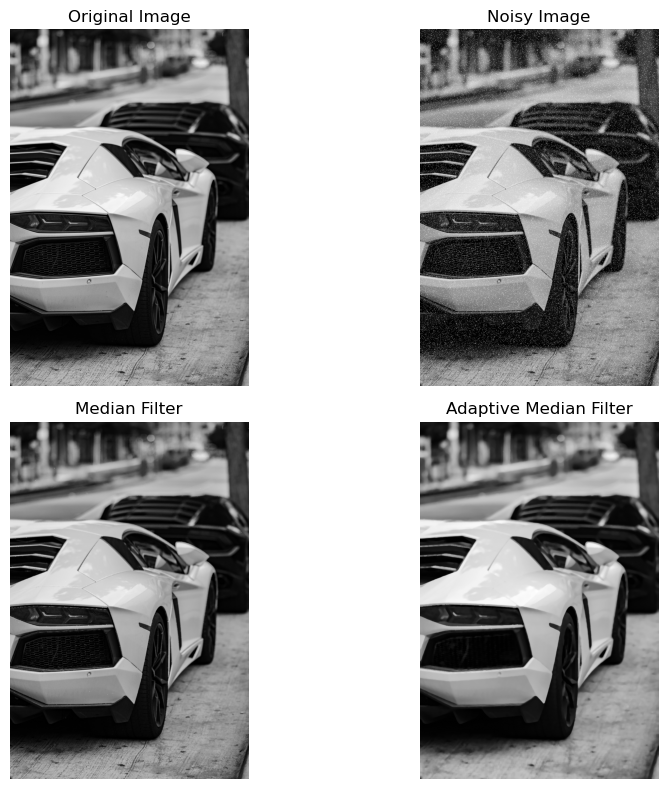

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('car.jpg', 0)

if img is None:
    print("Image not found!")
    exit()
Smin = int(input("Enter initial window size (odd number): "))
Smax = int(input("Enter maximum window size (odd number): "))

if Smin < 3 or Smin % 2 == 0 or Smax < Smin or Smax % 2 == 0:
    raise ValueError("Enter valid odd window sizes, with Smax >= Smin.")

noisy = cv2.medianBlur(img, 1)
noise = np.random.choice([0, 255, -1], img.shape, p=[0.05, 0.05, 0.90])
noisy = img.astype(np.int16) + noise
noisy = np.clip(noisy, 0, 255).astype(np.uint8)

def adaptive_median(image, Smin, Smax):

    rows, cols = image.shape
    output = np.zeros_like(image)

    for i in range(rows):
        for j in range(cols):

            size = Smin
            pixel = image[i, j]

            while size <= Smax:

                pad = size // 2

                y1 = max(0, i - pad)
                y2 = min(rows, i + pad + 1)
                x1 = max(0, j - pad)
                x2 = min(cols, j + pad + 1)

                window = image[y1:y2, x1:x2]

                zmin = np.min(window)
                zmax = np.max(window)
                zmed = np.median(window)

                A1 = zmed - zmin
                A2 = zmed - zmax

                if A1 > 0 and A2 < 0:

                    B1 = pixel - zmin
                    B2 = pixel - zmax

                    if B1 > 0 and B2 < 0:
                        output[i, j] = pixel
                    else:
                        output[i, j] = zmed

                    break

                size += 2

            else:
                output[i, j] = zmed

    return output

median_result = cv2.medianBlur(noisy, 3)
adaptive_result = adaptive_median(noisy, Smin, Smax)
def calculate_psnr(original, result):

    mse = np.mean((original.astype(float) -
                   result.astype(float)) ** 2)

    if mse == 0:
        return float('inf')

    return 10 * np.log10((255 ** 2) / mse)


psnr_median = calculate_psnr(img, median_result)
psnr_adaptive = calculate_psnr(img, adaptive_result)

print("Median Filter PSNR:", psnr_median, "dB")
print("Adaptive Median Filter PSNR:", psnr_adaptive, "dB")
images = [img, noisy, median_result, adaptive_result]

titles = [
    'Original Image',
    'Noisy Image',
    'Median Filter',
    'Adaptive Median Filter'
]

plt.figure(figsize=(10, 8))

for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

Optimal Threshold Value: 96.0


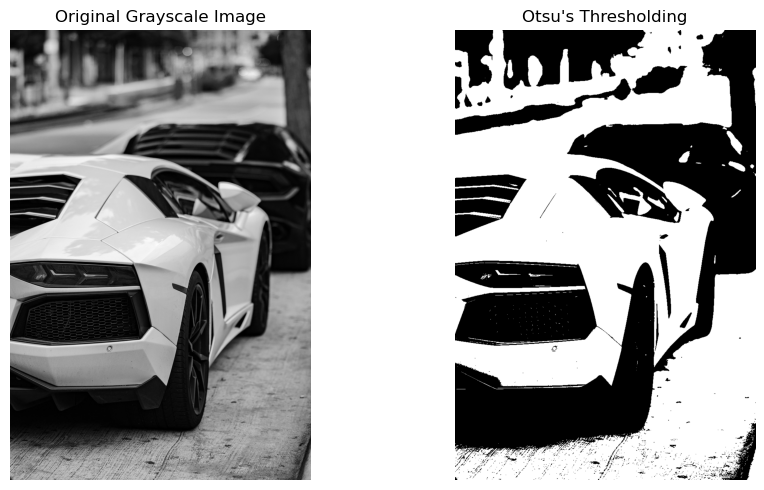

In [2]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('car.jpg', 0)

if img is None:
    print("Image not found!")
    exit()

threshold, segmented = cv2.threshold(
    img, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Optimal Threshold Value:", threshold)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(segmented, cmap='gray')
plt.title("Otsu's Thresholding")
plt.axis('off')
plt.tight_layout()
plt.show()